# Williams-Otto ReLU OMLT Baseline

The Williams-Otto benchmark models a continuous stirred-tank reactor fed by reactants A and B. The reaction network produces the desired products P and E through the intermediate C, while the side reaction forms the undesired waste product G. The operating decisions are the fresh-B feed rate `FB` and reactor temperature `TR`; together they determine the six reactor-effluent mass fractions.

The optimization objective is to maximize economic profit from P and E after accounting for feed costs, subject to operating limits on residual reactant A (`XA <= 0.12`) and waste G (`XG <= 0.08`). This notebook generates nominal simulator data, trains a compact ReLU neural-network surrogate, embeds it in Pyomo through OMLT, and compares its prediction and optimization behavior with the exact Williams-Otto process.

*Williams-Otto CSTR and reaction network: A + B produces C, C + B produces P and E, and P + C produces waste G.*

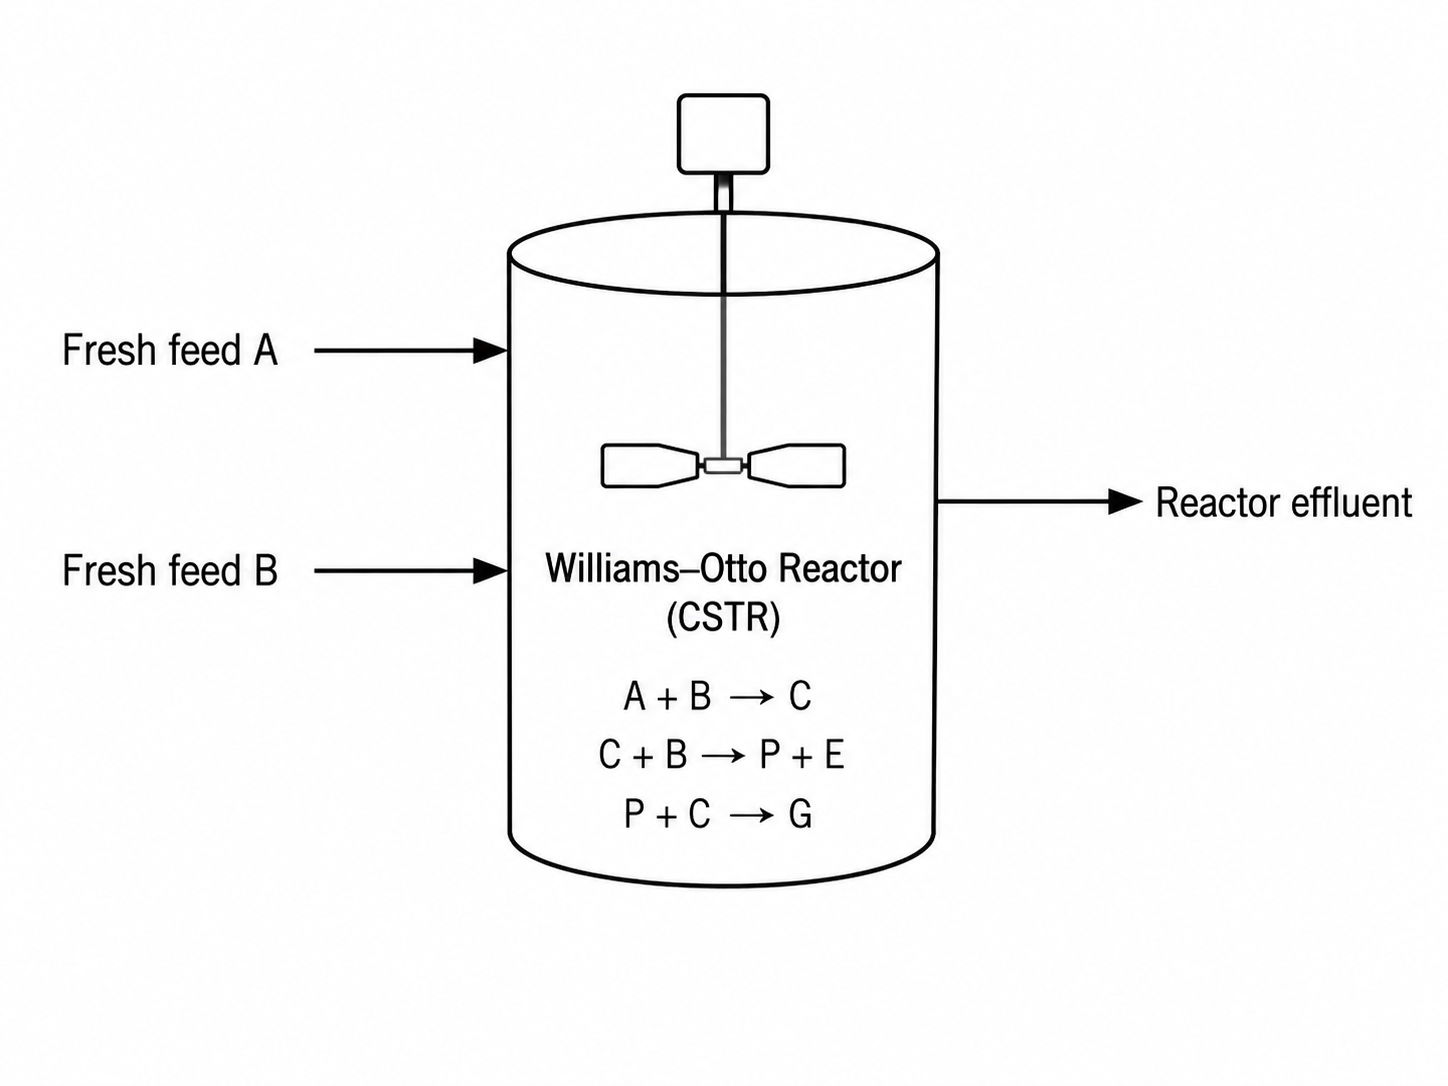

In [1]:
from pathlib import Path
from IPython.display import Image, display


def find_schematic(start: Path) -> Path:
    for candidate in (start, *start.parents):
        image = candidate / "images" / "williams-otto-reactor-schematic.png"
        if image.exists():
            return image
    raise FileNotFoundError("Could not locate the Williams-Otto reactor schematic.")


display(Image(filename=str(find_schematic(Path.cwd().resolve())), width=820))

In [2]:
from pathlib import Path
import sys

def find_project_root(start):
    for candidate in (start, *start.parents):
        pyproject = candidate / "pyproject.toml"
        if (candidate / "src" / "pwlnet").exists() and pyproject.exists():
            return candidate
    raise RuntimeError("Could not find the PWLNet project root from the notebook working directory.")

ROOT = find_project_root(Path.cwd().resolve())
for path in (ROOT / "src", ROOT / ".venv" / "Lib" / "site-packages"):
    value = str(path)
    if path.exists() and value not in sys.path:
        sys.path.insert(0, value)

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.ticker import LogLocator, LogFormatterSciNotation
import numpy as np
import pandas as pd
import pyomo.environ as pyo

plt.style.use("seaborn-v0_8-whitegrid")

In [3]:
from pwlnet import (
    KerasTrainer,
    build_prune_report,
    metrics_table,
    summarize,
    train_val_test_split,
)
from pwlnet.formulations.omlt import build_omlt_block, evaluate_block
from pwlnet.processes.williams_otto import (
    EXACT_OPTIMUM,
    INPUT_NAMES,
    OUTPUT_NAMES,
    WilliamsOttoParameters,
    generate_dataset,
    solve_steady_state,
)
from pwlnet.processes.williams_otto.pyomo_model import (
    build_surrogate_optimization_model,
    solve_surrogate_optimization_model,
)
from pwlnet.utils.exceptions import SolverNotAvailableError

params = WilliamsOttoParameters()

# Shared experiment configuration (identical across notebooks 01-03):
# 150 Latin-hypercube samples split 60/20/20 into train/validation/test
# with one fixed seed, so all three notebooks train and evaluate on the
# exact same partitions.
RANDOM_SEED = 7
DATA_CONFIG = dict(n_samples=150, method="lhs", random_state=RANDOM_SEED)
VAL_SIZE, TEST_SIZE = 0.2, 0.2

data = generate_dataset(**DATA_CONFIG, as_frame=True)
split = train_val_test_split(data, val_size=VAL_SIZE, test_size=TEST_SIZE, random_state=RANDOM_SEED)
train_df, val_df, test_df = split.train, split.validation, split.test


def split_xy(frame):
    return frame[INPUT_NAMES].to_numpy(dtype=float), frame[OUTPUT_NAMES].to_numpy(dtype=float)


X_train, y_train = split_xy(train_df)
X_val, y_val = split_xy(val_df)
X_test, y_test = split_xy(test_df)

# Dense regular 21x21 grid for landscape contour plots (pivot-based
# contouring needs a full mesh; the LHS samples are scattered).
plot_grid = generate_dataset(n_samples=441, method="grid", random_state=RANDOM_SEED, as_frame=True)

print(f"data: {len(data)} samples -> train {len(train_df)} / val {len(val_df)} / test {len(test_df)}")
data.head()


data: 150 samples -> train 90 / val 30 / test 30


,FB,TR,XA,XB,XC,XE,XG,XP,profit,residual_inf_norm
0,5.747498,77.420557,0.104888,0.511495,0.022780,0.221769,0.042276,0.096792,-24.799879,2.220446e-16
1,6.944486,80.554959,0.084438,0.564812,0.017969,0.205918,0.035855,0.091007,-95.868952,9.992007e-16
2,4.053997,89.025289,0.104188,0.329238,0.017761,0.307018,0.132429,0.109366,84.371330,7.616130e-14
3,6.439895,86.835754,0.074597,0.512648,0.014399,0.239701,0.058208,0.100448,1.033706,3.230749e-14
4,6.744059,85.506413,0.074986,0.534479,0.014853,0.228195,0.050086,0.097402,-30.859799,5.329071e-14


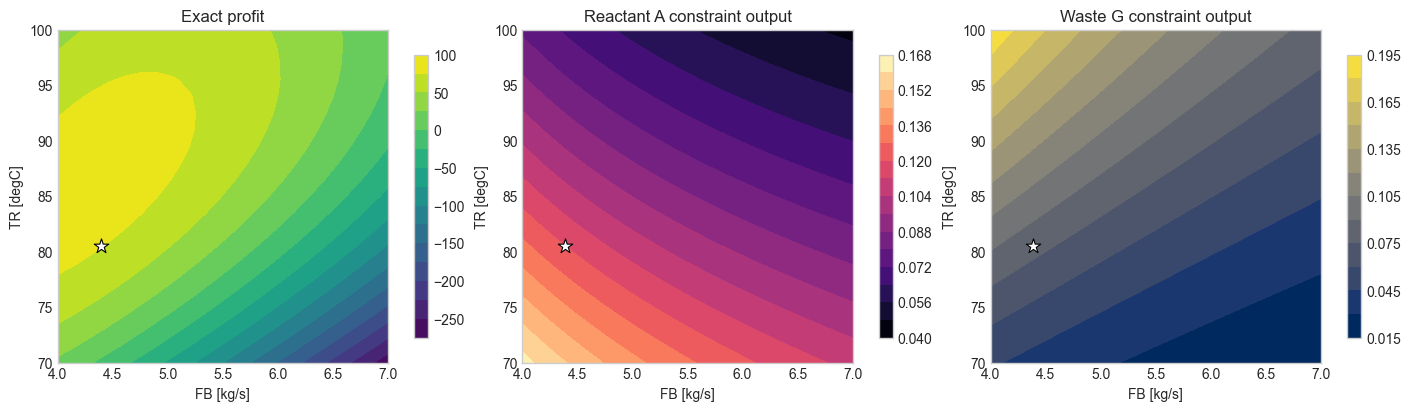

In [4]:
def grid_values(frame, column):
    table = frame.pivot(index="TR", columns="FB", values=column).sort_index()
    return table.columns.to_numpy(dtype=float), table.index.to_numpy(dtype=float), table.to_numpy(dtype=float)

fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
for ax, column, title, cmap in zip(
    axes,
    ["profit", "XA", "XG"],
    ["Exact profit", "Reactant A constraint output", "Waste G constraint output"],
    ["viridis", "magma", "cividis"],
):
    fb_grid, tr_grid, z = grid_values(plot_grid, column)
    contour = ax.contourf(fb_grid, tr_grid, z, levels=14, cmap=cmap)
    ax.scatter([4.3894], [80.495], marker="*", s=120, color="white", edgecolor="black", linewidth=0.8)
    ax.set_title(title)
    ax.set_xlabel("FB [kg/s]")
    ax.set_ylabel("TR [degC]")
    fig.colorbar(contour, ax=ax, shrink=0.85)

plt.show()

## Penalizing the constraint outputs more

The economic optimum sits right on the operating limits `XA <= 0.12` and `XG <= 0.08`, so the surrogate is only useful if it reproduces **XA** and **XG** accurately near those boundaries. A plain MSE weights all six mass fractions equally, letting the network trade constraint accuracy for a better fit on the unconstrained outputs.

Below we subclass `KerasTrainer` so the two constraint outputs are penalized `CONSTRAINT_WEIGHT`× more than the rest. The weights are normalized to mean 1.0, so the overall loss magnitude (and effective learning rate) match the unweighted baseline — only the *relative* emphasis changes. Later, the learned `XA = 0.12` and `XG = 0.08` boundaries are overlaid (dashed) on the exact limits (solid) so the constraint fit can be read straight off the optimization plots.

In [5]:
# Penalize the two outputs that appear in the operating limits (XA, XG) more
# heavily than the rest. The weight vector lives in OUTPUT_NAMES order.
CONSTRAINT_OUTPUTS = ["XA", "XG"]   # outputs that appear in XA <= 0.12, XG <= 0.08
CONSTRAINT_WEIGHT = 8.0             # how much more the constraint outputs are penalized

output_loss_weights = np.ones(len(OUTPUT_NAMES))
for _name in CONSTRAINT_OUTPUTS:
    output_loss_weights[OUTPUT_NAMES.index(_name)] = CONSTRAINT_WEIGHT


class ConstraintWeightedTrainer(KerasTrainer):
    """KerasTrainer whose loss scales each output by ``output_loss_weights``.

    The base trainer compiles a scalar ``mse``/``mae`` loss that weights all
    outputs equally. Here we recompile with a weighted version (in the same
    scaled space) so selected outputs -- the constraint mass fractions -- are
    penalized more. Weights are renormalized to mean 1.0 so the loss magnitude,
    and therefore the effective learning rate, stays comparable to the baseline.
    """

    def __init__(self, *args, output_loss_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.output_loss_weights = (
            None if output_loss_weights is None
            else np.asarray(output_loss_weights, dtype=float)
        )

    def _build_model(self, keras, n_inputs, n_outputs):
        model = super()._build_model(keras, n_inputs, n_outputs)
        if self.output_loss_weights is None:
            return model
        if self.output_loss_weights.shape != (n_outputs,):
            raise ValueError(
                f"output_loss_weights must have shape ({n_outputs},), "
                f"got {self.output_loss_weights.shape}."
            )
        w = self.output_loss_weights * (n_outputs / self.output_loss_weights.sum())
        w_tensor = keras.ops.convert_to_tensor(w.astype("float32"))
        base_loss = self.loss

        def weighted_loss(y_true, y_pred):
            err = y_true - y_pred
            per_output = keras.ops.square(err) if base_loss == "mse" else keras.ops.abs(err)
            return keras.ops.mean(per_output * w_tensor)

        optimizer = (
            keras.optimizers.get(self.optimizer)
            if isinstance(self.optimizer, str)
            else self.optimizer
        )
        try:
            optimizer.learning_rate = self.learning_rate
        except AttributeError:  # pragma: no cover - exotic optimizer objects
            pass
        model.compile(optimizer=optimizer, loss=weighted_loss)
        return model


trainer = ConstraintWeightedTrainer(
    hidden_layers=[8,6],
    activation="relu",
    epochs=1000,
    batch_size=16,
    early_stopping_patience=50,
    random_seed=RANDOM_SEED,
    verbose=0,
    output_loss_weights=output_loss_weights,
)
network = trainer.fit(X_train, y_train, validation_data=(X_val, y_val))

print(summarize(network))
print(f"Keras/core max prediction difference: {trainer.equivalence_error_:.3e}")
print(
    "per-output loss weights: "
    + ", ".join(f"{n}={w:g}" for n, w in zip(OUTPUT_NAMES, output_loss_weights))
)

# Train/validation/test prediction quality (MAE, MSE, RMSE, R2).
metrics = metrics_table(
    {
        "train": (y_train, network.predict(X_train)),
        "validation": (y_val, network.predict(X_val)),
        "test": (y_test, network.predict(X_test)),
    }
)

# Per-output test MAE, so the effect of up-weighting XA/XG is visible.
per_output_mae = np.abs(network.predict(X_test) - y_test).mean(axis=0)
print("per-output test MAE:")
for n, mae in zip(OUTPUT_NAMES, per_output_mae):
    tag = "  <-- constraint (up-weighted)" if n in CONSTRAINT_OUTPUTS else ""
    print(f"  {n}: {mae:.3e}{tag}")

metrics


NetworkDefinition: 2 inputs -> 6 outputs, 3 layers, 14 hidden neurons, 120 parameters
layer   n_in  n_out activation   params
    0      2      8       relu       24
    1      8      6       relu       54
    2      6      6     linear       42
Keras/core max prediction difference: 3.166e-08
per-output loss weights: XA=8, XB=1, XC=1, XE=1, XG=8, XP=1
per-output test MAE:
  XA: 5.876e-04  <-- constraint (up-weighted)
  XB: 2.475e-03
  XC: 2.070e-04
  XE: 1.346e-03
  XG: 1.188e-03  <-- constraint (up-weighted)
  XP: 6.258e-04


,split,MAE,MSE,RMSE,R2,n_samples
0,train,0.000776,0.000001,0.001144,0.999071,90
1,validation,0.001128,0.000004,0.001880,0.997265,30
2,test,0.001071,0.000003,0.001683,0.997869,30


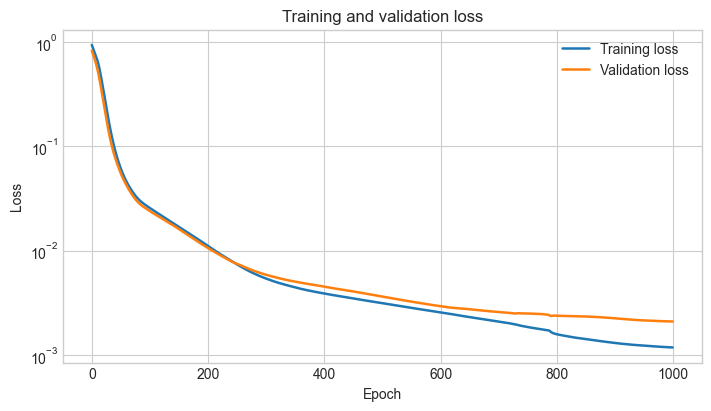

In [6]:
history = trainer.history_ or {}

fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)

ax.plot(history.get("loss", []),  linewidth=1.8, label="Training loss")

if "val_loss" in history:
    ax.plot(history["val_loss"],  linewidth=1.8, label="Validation loss")

ax.set_title("Training and validation loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_yscale("log")
ax.legend()

plt.show()

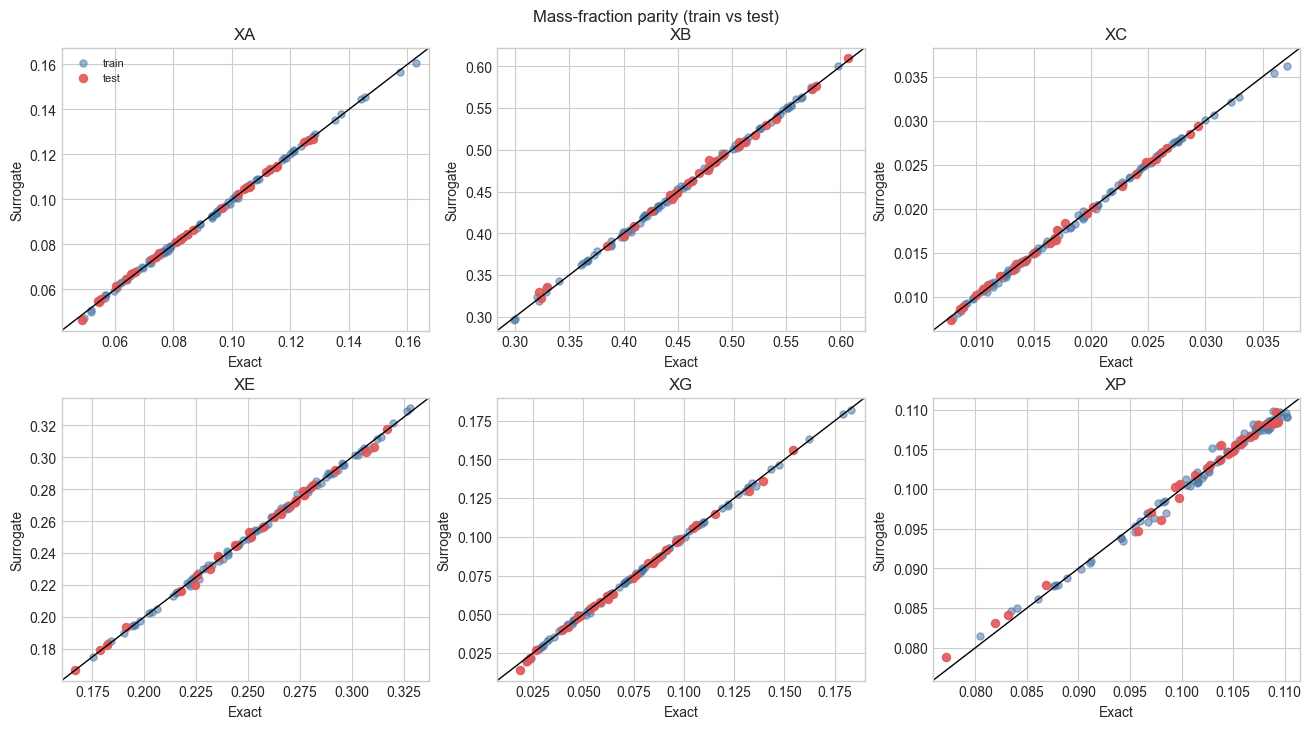

In [7]:
pred_train = network.predict(X_train)
pred_test = network.predict(X_test)

fig, axes = plt.subplots(2, 3, figsize=(13, 7), constrained_layout=True)
for ax, name, j in zip(axes.ravel(), OUTPUT_NAMES, range(len(OUTPUT_NAMES))):
    ax.scatter(y_train[:, j], pred_train[:, j], s=26, alpha=0.55, color="#4e79a7", label="train")
    ax.scatter(y_test[:, j], pred_test[:, j], s=34, alpha=0.9, color="#e15759", label="test")
    cat = np.concatenate([y_train[:, j], y_test[:, j], pred_train[:, j], pred_test[:, j]])
    lo, hi = float(cat.min()), float(cat.max())
    pad = 0.04 * max(hi - lo, 1e-6)
    ax.plot([lo - pad, hi + pad], [lo - pad, hi + pad], color="black", linewidth=1.0)
    ax.set_xlim(lo - pad, hi + pad)
    ax.set_ylim(lo - pad, hi + pad)
    ax.set_title(name)
    ax.set_xlabel("Exact")
    ax.set_ylabel("Surrogate")
axes.ravel()[0].legend(loc="upper left", fontsize=8)
fig.suptitle("Mass-fraction parity (train vs test)", y=1.02)
plt.show()


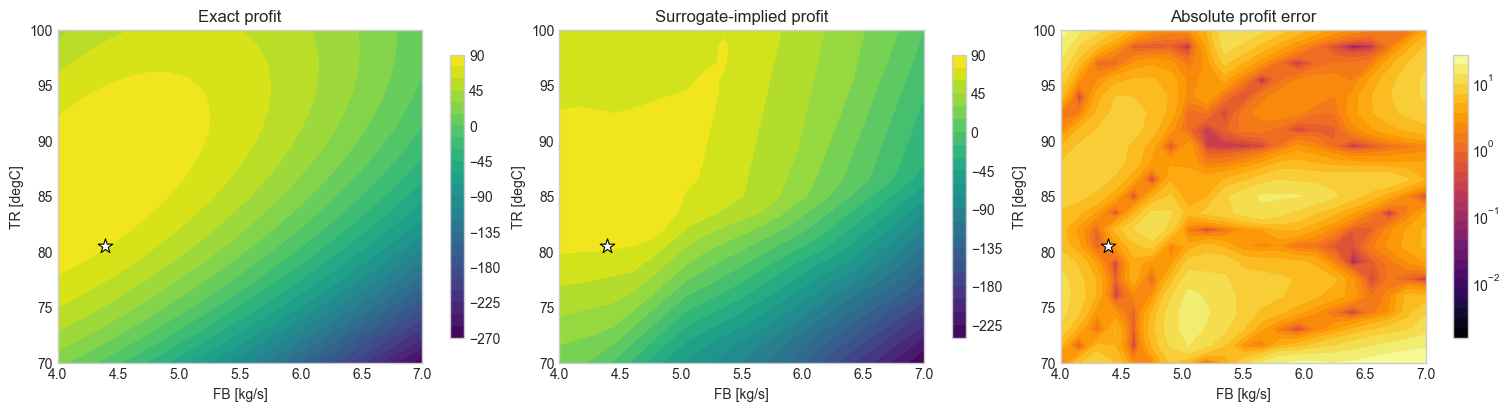

In [8]:
plot_data = plot_grid.copy()
pred_grid = network.predict(plot_data[INPUT_NAMES].to_numpy(dtype=float))
for i, name in enumerate(OUTPUT_NAMES):
    plot_data[f"{name}_pred"] = pred_grid[:, i]

flow = params.fa + plot_data["FB"].to_numpy(dtype=float)
plot_data["profit_pred"] = (
    (params.price_p * plot_data["XP_pred"].to_numpy(dtype=float)
     + params.price_e * plot_data["XE_pred"].to_numpy(dtype=float))
    * flow
    - params.cost_a * params.fa
    - params.cost_b * plot_data["FB"].to_numpy(dtype=float)
)
plot_data["profit_abs_error"] = np.abs(plot_data["profit_pred"] - plot_data["profit"])

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)

for ax, column, title, cmap in zip(
    axes,
    ["profit", "profit_pred", "profit_abs_error"],
    ["Exact profit", "Surrogate-implied profit", "Absolute profit error"],
    ["viridis", "viridis", "inferno"],
):
    fb_grid, tr_grid, z = grid_values(plot_data, column)

    if column == "profit_abs_error":
        positive = z[np.isfinite(z) & (z > 0)]

        eps = positive.min() / 1 if positive.size else 1e-12
        z_plot = np.where(z > 0, z, eps)

        vmin = z_plot.min()
        vmax = z_plot.max()

        levels = np.logspace(np.log10(vmin), np.log10(vmax), 30)

        contour = ax.contourf(
            fb_grid,
            tr_grid,
            z_plot,
            levels=levels,
            cmap=cmap,
            norm=LogNorm(vmin=vmin, vmax=vmax)
        )

        cbar = fig.colorbar(contour, ax=ax, shrink=0.85)
        cbar.locator = LogLocator(base=10, numticks=20)
        cbar.formatter = LogFormatterSciNotation(base=10)
        cbar.update_ticks()

    else:
        contour = ax.contourf(
            fb_grid,
            tr_grid,
            z,
            levels=30,
            cmap=cmap
        )

        fig.colorbar(contour, ax=ax, shrink=0.85)

    ax.scatter(
        [EXACT_OPTIMUM["FB"]],
        [EXACT_OPTIMUM["TR"]],
        marker="*",
        s=120,
        color="white",
        edgecolor="black",
        linewidth=0.8
    )

    ax.set_title(title)
    ax.set_xlabel("FB [kg/s]")
    ax.set_ylabel("TR [degC]")

plt.show()

In [9]:
omlt_model, omlt_block = build_omlt_block(network, formulation="relu_bigm")
sample_x = X_train[0]
core_y = network.predict(sample_x)
omlt_y = evaluate_block(omlt_model, omlt_block, sample_x)

print("sample input:", dict(zip(INPUT_NAMES, sample_x)))
print("max OMLT/core difference:", float(np.max(np.abs(omlt_y - core_y))))

sample input: {'FB': np.float64(6.41976411948915), 'TR': np.float64(76.76151957120294)}
max OMLT/core difference: 1.1102230246251565e-16


In [10]:
report = build_prune_report(network)
state = solve_steady_state(4.3894, 80.495)

print(report.to_dict())
print(f"WO optimum sanity: XA={state.x[0]:.5f}, XG={state.x[4]:.5f}, profit={state.profit:.2f}")

{'n_inputs': 2, 'n_outputs': 6, 'n_layers': 3, 'n_hidden_neurons': 14, 'n_parameters': 120, 'formulation_estimates': {'relu_bigm': {'n_continuous_vars': 36, 'n_binary_vars': 14, 'n_constraints': 76}, 'tanh_exact': {'n_continuous_vars': 36, 'n_binary_vars': 0, 'n_constraints': 34}}, 'relu_state_counts': {'dead': 0, 'always_active': 0, 'uncertain': 14}, 'saturated_tanh_neurons': 0, 'notes': []}
WO optimum sanity: XA=0.12000, XG=0.08000, profit=75.82


In [11]:
surrogate_model, surrogate_block = build_surrogate_optimization_model(network, formulation="relu_bigm")
n_vars = sum(1 for _ in surrogate_model.component_data_objects(pyo.Var, descend_into=True))
n_cons = sum(1 for _ in surrogate_model.component_data_objects(pyo.Constraint, descend_into=True))

print(f"Embedded surrogate model: {n_vars} variables, {n_cons} constraints")
print("Objective component:", surrogate_model.objective.name)

Embedded surrogate model: 86 variables, 197 constraints
Objective component: objective


## Embedded surrogate optimization

The default ReLU solve uses HiGHS with McCormick envelopes for the profit products, so the surrogate objective is a MILP-compatible relaxation. The exact Williams-Otto evaluation at the selected point is the physical sanity check.

In [12]:
# Default open-source path. To use Gurobi instead, switch to "gurobi" or "appsi_gurobi".
solver_name = "appsi_highs"
# solver_name = "gurobi"  # or "appsi_gurobi"

try:
    solve_result = solve_surrogate_optimization_model(network, include_operating_constraints=False, solver=solver_name)
except SolverNotAvailableError as exc:
    print(f"Skipping solve because solver {solver_name!r} is unavailable: {exc}")
else:
    print(f"solver: {solve_result.solver_name}")
    print(f"status: {solve_result.status}")
    print(f"termination: {solve_result.termination_condition}")
    print(f"selected FB={solve_result.fb:.4f}, TR={solve_result.tr:.3f}")
    print(
        "predicted outputs:",
        {key: round(solve_result.predicted_outputs[key], 5) for key in ["XA", "XG", "XP", "XE"]},
    )
    print(f"surrogate objective/profit: {solve_result.surrogate_profit:.2f}")
    print(
        f"exact at selected point: profit={solve_result.exact_profit:.2f}, "
        f"feasible={solve_result.exact_feasible}"
    )

    comparison = pd.DataFrame(solve_result.comparison_rows())
    comparison[["case", "FB", "TR", "profit", "XA", "XG", "feasible"]]


solver: appsi_highs
status: ok
termination: optimal
selected FB=4.8224, TR=83.625
predicted outputs: {'XA': 0.10109, 'XG': 0.08015, 'XP': 0.10992, 'XE': 0.2753}
surrogate objective/profit: 85.50
exact at selected point: profit=73.70, feasible=False


### Optimization visualization

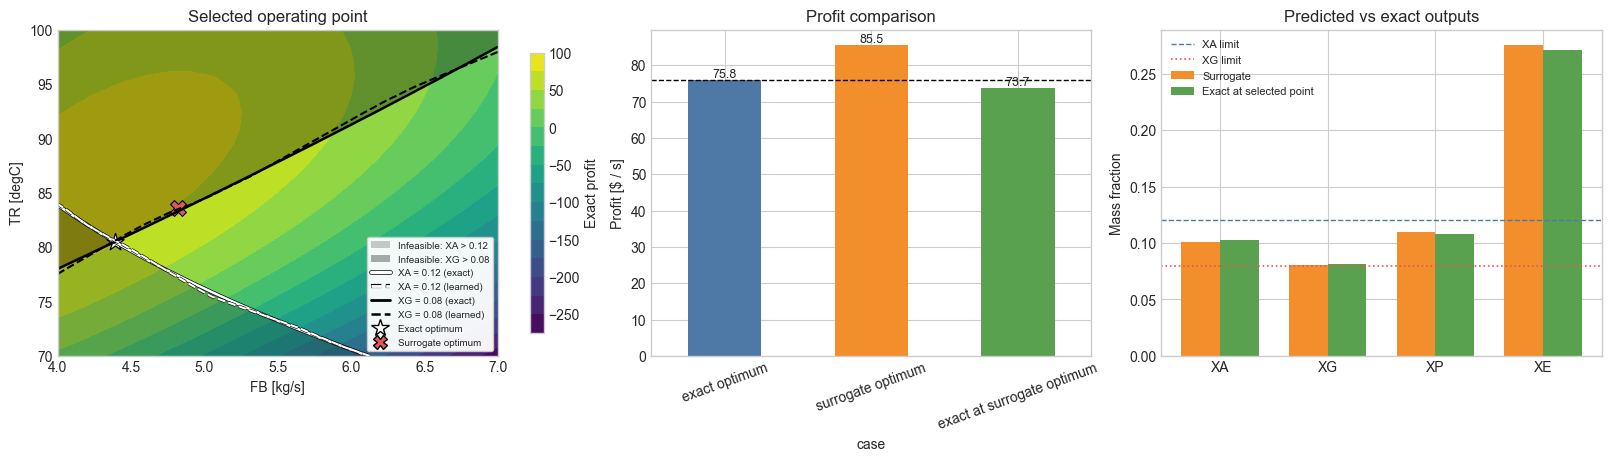

In [13]:
if "solve_result" not in globals():
    print("No optimization result available to visualize.")
else:
    from matplotlib.lines import Line2D
    from matplotlib.patches import Patch
    import matplotlib.patheffects as pe

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)

    fb_grid, tr_grid, exact_profit_grid = grid_values(plot_data, "profit")
    _, _, xa_grid = grid_values(plot_data, "XA")
    _, _, xg_grid = grid_values(plot_data, "XG")
    # Learned (surrogate-predicted) constraint fields, from cell f44fae0e.
    _, _, xa_pred_grid = grid_values(plot_data, "XA_pred")
    _, _, xg_pred_grid = grid_values(plot_data, "XG_pred")

    contour = axes[0].contourf(fb_grid, tr_grid, exact_profit_grid, levels=16, cmap="viridis")
    xa_upper = float(np.nanmax(xa_grid))
    xg_upper = float(np.nanmax(xg_grid))
    if xa_upper > params.xa_max:
        axes[0].contourf(
            fb_grid,
            tr_grid,
            xa_grid,
            levels=[params.xa_max, xa_upper],
            colors=["#171717"],
            alpha=0.22,
            antialiased=True,
        )
    if xg_upper > params.xg_max:
        axes[0].contourf(
            fb_grid,
            tr_grid,
            xg_grid,
            levels=[params.xg_max, xg_upper],
            colors=["#000000"],
            alpha=0.32,
            antialiased=True,
        )
    xa_line = axes[0].contour(
        fb_grid,
        tr_grid,
        xa_grid,
        levels=[params.xa_max],
        colors="white",
        linewidths=1.8,
    )
    xg_line = axes[0].contour(
        fb_grid,
        tr_grid,
        xg_grid,
        levels=[params.xg_max],
        colors="black",
        linewidths=1.8,
    )
    xa_line.set_path_effects([pe.Stroke(linewidth=2.8, foreground="black"), pe.Normal()])
    # Learned constraint boundaries (dashed) -- how the surrogate places the
    # XA = 0.12 and XG = 0.08 limits versus the exact (solid) ones.
    xa_pred_line = axes[0].contour(
        fb_grid,
        tr_grid,
        xa_pred_grid,
        levels=[params.xa_max],
        colors="white",
        linewidths=1.5,
        linestyles="dashed",
    )
    xa_pred_line.set_path_effects([pe.Stroke(linewidth=2.4, foreground="black"), pe.Normal()])
    axes[0].contour(
        fb_grid,
        tr_grid,
        xg_pred_grid,
        levels=[params.xg_max],
        colors="black",
        linewidths=1.5,
        linestyles="dashed",
    )
    axes[0].scatter([solve_result.exact_optimum["FB"]], [solve_result.exact_optimum["TR"]], marker="*", s=170, color="white", edgecolor="black", linewidth=0.9)
    axes[0].scatter([solve_result.fb], [solve_result.tr], marker="X", s=130, color="#e15759", edgecolor="black", linewidth=0.8)
    axes[0].set_title("Selected operating point")
    axes[0].set_xlabel("FB [kg/s]")
    axes[0].set_ylabel("TR [degC]")
    fig.colorbar(contour, ax=axes[0], shrink=0.86, label="Exact profit")

    legend_handles = [
        Patch(facecolor="#171717", alpha=0.22, label="Infeasible: XA > 0.12"),
        Patch(facecolor="#000000", alpha=0.32, label="Infeasible: XG > 0.08"),
        Line2D([0], [0], color="white", lw=2.4, label="XA = 0.12 (exact)", path_effects=[pe.Stroke(linewidth=3.4, foreground="black"), pe.Normal()]),
        Line2D([0], [0], color="white", lw=2.0, linestyle="--", label="XA = 0.12 (learned)", path_effects=[pe.Stroke(linewidth=3.0, foreground="black"), pe.Normal()]),
        Line2D([0], [0], color="black", lw=2.0, label="XG = 0.08 (exact)"),
        Line2D([0], [0], color="black", lw=1.8, linestyle="--", label="XG = 0.08 (learned)"),
        Line2D([0], [0], marker="*", color="white", markeredgecolor="black", markersize=13, linestyle="None", label="Exact optimum"),
        Line2D([0], [0], marker="X", color="#e15759", markeredgecolor="black", markersize=10, linestyle="None", label="Surrogate optimum"),
    ]
    axes[0].legend(handles=legend_handles, loc="lower right", frameon=True, framealpha=0.95, fontsize=7)

    profit_rows = pd.DataFrame(solve_result.comparison_rows())
    profit_bars = profit_rows.set_index("case")["profit"]
    colors = ["#4e79a7", "#f28e2b", "#59a14f"]
    profit_bars.plot(kind="bar", ax=axes[1], color=colors, rot=20)
    axes[1].set_title("Profit comparison")
    axes[1].set_ylabel("Profit [$ / s]")
    axes[1].axhline(solve_result.exact_optimum["profit"], color="black", linestyle="--", linewidth=1.0)
    for patch in axes[1].patches:
        height = patch.get_height()
        axes[1].annotate(f"{height:.1f}", (patch.get_x() + patch.get_width() / 2, height), ha="center", va="bottom", fontsize=9)

    output_names = ["XA", "XG", "XP", "XE"]
    x = np.arange(len(output_names))
    width = 0.36
    axes[2].bar(x - width / 2, [solve_result.predicted_outputs[name] for name in output_names], width, label="Surrogate", color="#f28e2b")
    axes[2].bar(x + width / 2, [solve_result.exact_outputs[name] for name in output_names], width, label="Exact at selected point", color="#59a14f")
    axes[2].axhline(params.xa_max, color="#4e79a7", linestyle="--", linewidth=1.0, label="XA limit")
    axes[2].axhline(params.xg_max, color="#e15759", linestyle=":", linewidth=1.2, label="XG limit")
    axes[2].set_xticks(x)
    axes[2].set_xticklabels(output_names)
    axes[2].set_title("Predicted vs exact outputs")
    axes[2].set_ylabel("Mass fraction")
    axes[2].legend(fontsize=8)

    plt.show()

## Operating constraints: constrained vs unconstrained

All three embedding methods in this benchmark suite express the surrogate
outputs as decision variables of the Pyomo model, so the Williams-Otto
operating constraints `XA <= 0.12` and `XG <= 0.08` are **linear constraints
on those output variables**. They can therefore be added to every method:

| method | embedding | problem class with XA/XG limits |
|---|---|---|
| ReLU big-M | OMLT `relu_bigm` | MILP |
| exact tanh | OMLT `tanh_exact` | NLP |
| PWL-tanh big-M | `tanh_pwl_bigm` | MILP |

Below we solve the embedded problem **without** the operating constraints
(pure profit maximization) and **with** them, then compare the selected
operating points and the solver time.

In [14]:
import time

con = solve_surrogate_optimization_model(
    network, include_operating_constraints=True, params=params, formulation="relu_bigm", solver="appsi_highs"
)
unc = solve_surrogate_optimization_model(
    network, include_operating_constraints=False, params=params, formulation="relu_bigm", solver="appsi_highs"
)


def _constraint_row(case, r):
    return {
        "case": case,
        "FB": r.fb,
        "TR": r.tr,
        "surrogate profit": r.surrogate_profit,
        "true profit": r.exact_profit,
        "XA": r.predicted_outputs["XA"],
        "XG": r.predicted_outputs["XG"],
        "true feasible": r.exact_feasible,
        "solve time [s]": r.solve_seconds,
    }


constraint_table = pd.DataFrame(
    [
        _constraint_row("unconstrained", unc),
        _constraint_row("constrained (XA<=0.12, XG<=0.08)", con),
    ]
)
constraint_table

,case,FB,TR,surrogate profit,true profit,XA,XG,true feasible,solve time [s]
0,unconstrained,4.822376,83.624854,85.502780,73.701977,0.101094,0.080146,False,0.243533
1,"constrained (XA<=0.12, XG<=0.08)",4.820947,83.585215,85.527204,73.615232,0.101239,0.080000,False,0.182057


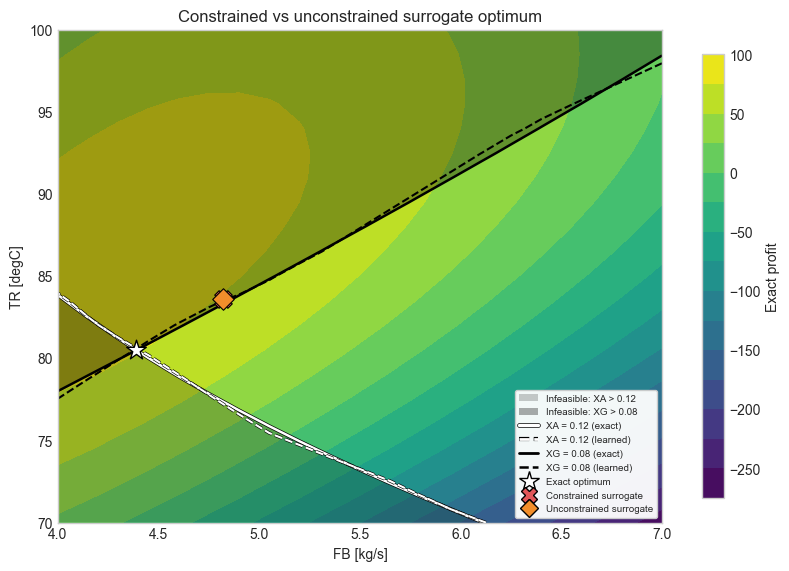

In [15]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import matplotlib.patheffects as pe

fig, ax = plt.subplots(figsize=(7.8, 5.6), constrained_layout=True)

fb_grid, tr_grid, profit_grid = grid_values(plot_data, "profit")
_, _, xa_grid = grid_values(plot_data, "XA")
_, _, xg_grid = grid_values(plot_data, "XG")
# Learned (surrogate-predicted) constraint fields, from cell f44fae0e.
_, _, xa_pred_grid = grid_values(plot_data, "XA_pred")
_, _, xg_pred_grid = grid_values(plot_data, "XG_pred")

contour = ax.contourf(fb_grid, tr_grid, profit_grid, levels=16, cmap="viridis")
xa_upper = float(np.nanmax(xa_grid))
xg_upper = float(np.nanmax(xg_grid))
if xa_upper > params.xa_max:
    ax.contourf(fb_grid, tr_grid, xa_grid, levels=[params.xa_max, xa_upper], colors=["#171717"], alpha=0.22, antialiased=True)
if xg_upper > params.xg_max:
    ax.contourf(fb_grid, tr_grid, xg_grid, levels=[params.xg_max, xg_upper], colors=["#000000"], alpha=0.32, antialiased=True)
xa_line = ax.contour(fb_grid, tr_grid, xa_grid, levels=[params.xa_max], colors="white", linewidths=1.8)
ax.contour(fb_grid, tr_grid, xg_grid, levels=[params.xg_max], colors="black", linewidths=1.8)
xa_line.set_path_effects([pe.Stroke(linewidth=2.8, foreground="black"), pe.Normal()])
# Learned constraint boundaries (dashed): the surrogate's own XA = 0.12 and
# XG = 0.08 contours, for comparison against the exact (solid) limits.
xa_pred_line = ax.contour(fb_grid, tr_grid, xa_pred_grid, levels=[params.xa_max], colors="white", linewidths=1.5, linestyles="dashed")
xa_pred_line.set_path_effects([pe.Stroke(linewidth=2.4, foreground="black"), pe.Normal()])
ax.contour(fb_grid, tr_grid, xg_pred_grid, levels=[params.xg_max], colors="black", linewidths=1.5, linestyles="dashed")

ax.scatter([con.exact_optimum["FB"]], [con.exact_optimum["TR"]], marker="*", s=220, color="white", edgecolor="black", linewidth=1.0, zorder=6)
ax.scatter([con.fb], [con.tr], marker="X", s=160, color="#e15759", edgecolor="black", linewidth=0.8, zorder=6)
ax.scatter([unc.fb], [unc.tr], marker="D", s=120, color="#f28e2b", edgecolor="black", linewidth=0.8, zorder=6)

ax.set_title("Constrained vs unconstrained surrogate optimum")
ax.set_xlabel("FB [kg/s]")
ax.set_ylabel("TR [degC]")
fig.colorbar(contour, ax=ax, shrink=0.9, label="Exact profit")

legend_handles = [
    Patch(facecolor="#171717", alpha=0.22, label="Infeasible: XA > 0.12"),
    Patch(facecolor="#000000", alpha=0.32, label="Infeasible: XG > 0.08"),
    Line2D([0], [0], color="white", lw=2.4, label="XA = 0.12 (exact)", path_effects=[pe.Stroke(linewidth=3.4, foreground="black"), pe.Normal()]),
    Line2D([0], [0], color="white", lw=2.0, linestyle="--", label="XA = 0.12 (learned)", path_effects=[pe.Stroke(linewidth=3.0, foreground="black"), pe.Normal()]),
    Line2D([0], [0], color="black", lw=2.0, label="XG = 0.08 (exact)"),
    Line2D([0], [0], color="black", lw=1.8, linestyle="--", label="XG = 0.08 (learned)"),
    Line2D([0], [0], marker="*", color="white", markeredgecolor="black", markersize=15, linestyle="None", label="Exact optimum"),
    Line2D([0], [0], marker="X", color="#e15759", markeredgecolor="black", markersize=11, linestyle="None", label="Constrained surrogate"),
    Line2D([0], [0], marker="D", color="#f28e2b", markeredgecolor="black", markersize=9, linestyle="None", label="Unconstrained surrogate"),
]
ax.legend(handles=legend_handles, loc="lower right", frameon=True, framealpha=0.95, fontsize=7)

plt.show()